In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

#Past Results

In [2]:
df = pd.read_csv("1976-2024-house.tab", sep=",", low_memory=False)   # the MIT .tab file is comma-separated
df.head()

,year,state,state_po,state_fips,state_cen,state_ic,office,district,stage,runoff,special,candidate,party,writein,mode,candidatevotes,totalvotes,unofficial,version,fusion_ticket
0,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,BILL DAVENPORT,DEMOCRAT,False,TOTAL,58906,157170,False,20250910,False
1,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,JACK EDWARDS,REPUBLICAN,False,TOTAL,98257,157170,False,20250910,False
2,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,WRITEIN,NaN,True,TOTAL,7,157170,False,20250910,False
3,1976,ALABAMA,AL,1,63,41,US HOUSE,2,GEN,False,False,J CAROLE KEAHEY,DEMOCRAT,False,TOTAL,66288,156362,False,20250910,False
4,1976,ALABAMA,AL,1,63,41,US HOUSE,2,GEN,False,False,"WILLIAM L \""BILL\"" DICKINSON",REPUBLICAN,False,TOTAL,90069,156362,False,20250910,False


# Filter Data

In [12]:
#get only NY and general elections
ny = df[(df.state_po == "NY") & (df.stage == "GEN")].copy()

# one row per candidate, NY candidates can appear on different party lines so add up votes
# the candidate's party is the line where they got the most votes
cand = ny.sort_values("candidatevotes", ascending=False).groupby(["year", "district", "candidate"])
                      .agg(votes=("candidatevotes", "sum"), party=("party", "first")).reset_index()
# selects the party sides (only Democrat and Republican in this election)
cand["side"] = cand.party.str[:3].map({"DEM": "D", "REP": "R"})

# keep only republican and dem candidates
cand = cand[cand["side"].isin(["D", "R"])]
# gets the lead democrat and republican in each election
votes = cand.groupby(["year", "district", "side"]).votes.max().unstack()

votes["margin"] = (votes.D - votes.R) / (votes.D + votes.R) * 100          # dem margin in pts for both sides
ny3_margin = votes.xs(3, level="district")["margin"]                       # NY-3 dem margin
other_ny = votes[votes.index.get_level_values("district") != 3]            # calculate votes for all other districts in NY
other_ny = other_ny.groupby(level="year")[["D", "R"]].sum()
other_ny["margin"] = (other_ny.D - other_ny.R) / (other_ny.D + other_ny.R) * 100     # NY statewide dem margin

ny3_vs_nystatewide = pd.DataFrame({"NY-3": ny3_margin, "NY Statewide (w/o NY-3)": other_ny["margin"]}).dropna()
ny3_vs_nystatewide = ny3_vs_nystatewide[ny3_vs_nystatewide.index >= 2012].round(1)
ny3_vs_nystatewide

,NY-3,NY Statewide (w/o NY-3)
year,,
2012,16.5,30.3
2014,9.6,12.9
2016,6.0,28.7
2018,18.0,37.3
2020,12.6,26.8
2022,-7.5,12.7
2024,3.6,15.4


# Comparing NY-3 vs The Rest of NY Pre and Post Redistricting

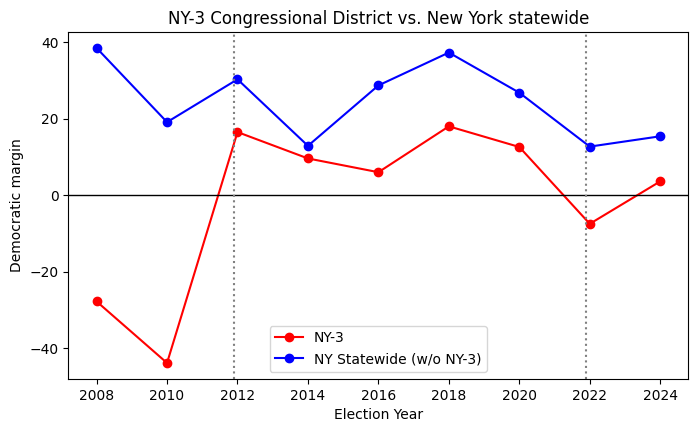

In [4]:
ny3_vs_nystatewide.plot(marker="o", figsize=(8, 4.5), color=["red", "blue"])
plt.axhline(0, color="black", lw=1)              # when margin is 0
plt.axvline(2021.9, color="gray", ls=":")        # new district map starts in 2022 following 2020
plt.axvline(2011.9, color="gray", ls=":")        # new district map in 2012 following 2010 census
plt.ylabel("Democratic margin")
plt.xlabel("Election Year")
plt.title("NY-3 vs. New York Statewide")
plt.show()

# Model Based on Historical Data

In [5]:
#same candidates as previous election --> baseline is 2024 election results
baseline = float(ny3_margin[2024])
baseline

3.576159671472413

In [29]:
# create a dataframe for the regression with ny3 and outside ny-3 ny votes
reg_df = pd.DataFrame({"ny3_margin": ny3_margin, "state_margin": other_ny["margin"]}).dropna()

reg_df = reg_df.loc[2012:2024].copy()
reg_df = reg_df[reg_df.index != 2022]    #remove 2022 outlier

#add incumbency dummy
reg_df["dem_incumbent"] = [1, 1, 0, 1, 1, 1]

#add campaign spending variable
reg_df["spending"] = [0.58, 0.54, 0.51, 0.62, 0.59, 0.91]

reg_df = reg_df.sort_index()
reg_df

,ny3_margin,state_margin,dem_incumbent,spending
year,,,,
2012,16.473470,30.258580,1,0.58
2014,9.593977,12.925952,1,0.54
2016,6.008103,28.705474,0,0.51
2018,17.957823,37.320816,1,0.62
2020,12.584551,26.789857,1,0.59
2024,3.576160,15.361457,1,0.91


In [30]:
#model
X = reg_df[["state_margin", "dem_incumbent", "spending"]]
X = sm.add_constant(X)
y = reg_df["ny3_margin"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             ny3_margin   R-squared:                       0.982
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     36.36
Date:                Tue, 03 Nov 2026   Prob (F-statistic):             0.0269
Time:                        04:06:00   Log-Likelihood:                -6.3663
No. Observations:                   6   AIC:                             20.73
Df Residuals:                       2   BIC:                             19.90
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             3.6136      3.481      1.038

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


#How closely our model fits the past results


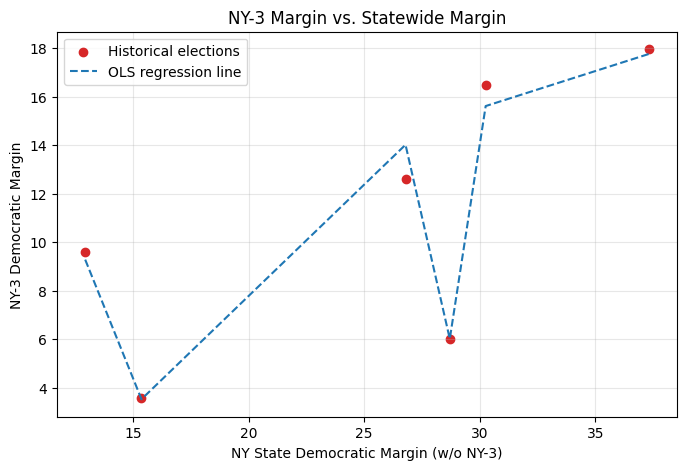

In [39]:
plot_df = reg_df.sort_values("state_margin")

plt.figure(figsize=(8, 5))
plt.scatter(reg_df["state_margin"], reg_df["ny3_margin"], color="tab:red", label="Historical elections")
plt.plot(plot_df["state_margin"], model.predict(X.loc[plot_df.index]), linestyle="--", label="OLS regression line")

plt.xlabel("NY State Democratic Margin (w/o NY-3)")
plt.ylabel("NY-3 Democratic Margin")
plt.title("NY-3 Margin vs. Statewide Margin")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Predict 2026 Election

In [40]:
#previous 7 years MOV with ny-3: 27.3%, 28.9%, 28.8%, 30.2%, 36.6%, 35.8%, 31.9% (ballotpedia)
#previous 7 years MOV without ny-3: 15.4%, 12.7%, 26.8%, 37.3%, 28.7%, 12.9%

#using october 2026 expected democratic margin in NY via MaristPolls for all NY voters
expected_state_margin = 16

#suozzi is an incumbent
expected_dem_incumbent = 1

#current spending as of october 2026 (ballotpedia)
expected_spending = .61

new_X = pd.DataFrame({"const": [1],
                      "state_margin": [expected_state_margin],
                      "incumbency": [expected_dem_incumbent],
                      "spending" : [expected_spending]})

prediction = model.get_prediction(new_X).summary_frame(alpha=0.05)

print(prediction)

    mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  9.253  0.814344        5.74916      12.756839      2.974093     15.531906


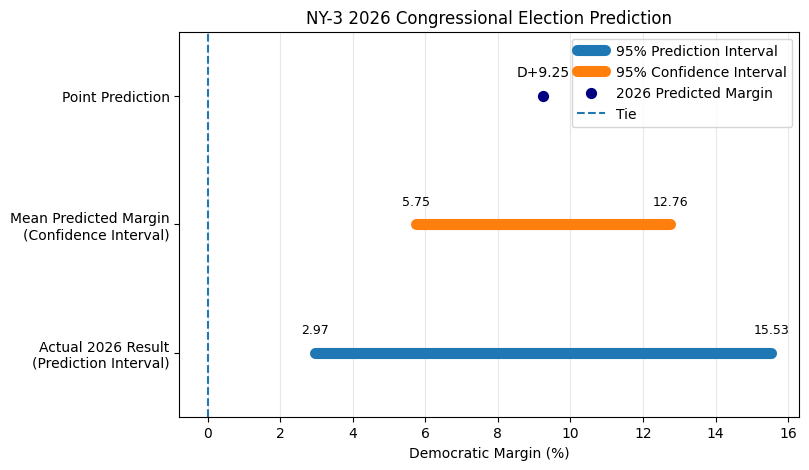

In [45]:
predicted_margin = prediction["mean"].iloc[0]

mean_lower = prediction["mean_ci_lower"].iloc[0]
mean_upper = prediction["mean_ci_upper"].iloc[0]

prediction_lower = prediction["obs_ci_lower"].iloc[0]
prediction_upper = prediction["obs_ci_upper"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 5))

# 95% prediction interval for the actual 2026 result
ax.plot([prediction_lower, prediction_upper], [1, 1], linewidth=8,
        solid_capstyle="round", label="95% Prediction Interval")

# 95% CI for the mean predicted margin
ax.plot([mean_lower, mean_upper], [2, 2], linewidth=8,
        solid_capstyle="round", label="95% Confidence Interval")

ax.scatter(predicted_margin, 3, color="navy", s=50,zorder=5,label="2026 Predicted Margin")

ax.text(predicted_margin, 3.15, f"D+{predicted_margin:.2f}", ha="center", fontsize=10)

ax.text(mean_lower, 2.15, f"{mean_lower:.2f}", ha="center", fontsize=9)
ax.text(mean_upper, 2.15, f"{mean_upper:.2f}", ha="center", fontsize=9)

ax.text(prediction_lower, 1.15, f"{prediction_lower:.2f}", ha="center", fontsize=9)
ax.text(prediction_upper, 1.15, f"{prediction_upper:.2f}", ha="center", fontsize=9)

ax.axvline(0, linestyle="--", linewidth=1.5,label="Tie")

ax.set_yticks([1, 2, 3])
ax.set_yticklabels(["Actual 2026 Result\n(Prediction Interval)",
                    "Mean Predicted Margin\n(Confidence Interval)",
                    "Point Prediction"])

ax.set_xlabel("Democratic Margin (%)")
ax.set_title("NY-3 2026 Congressional Election Prediction")
ax.set_ylim(0.5, 3.5)

ax.grid(axis="x", alpha=0.3)
ax.legend(loc="upper right")
plt.show()